<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None
               Age  Sex ChestPainType   RestingBP  Cholesterol   FastingBS  \
count   918.000000  918           918  918.000000   918.000000  918.000000   
unique         NaN    2             4    

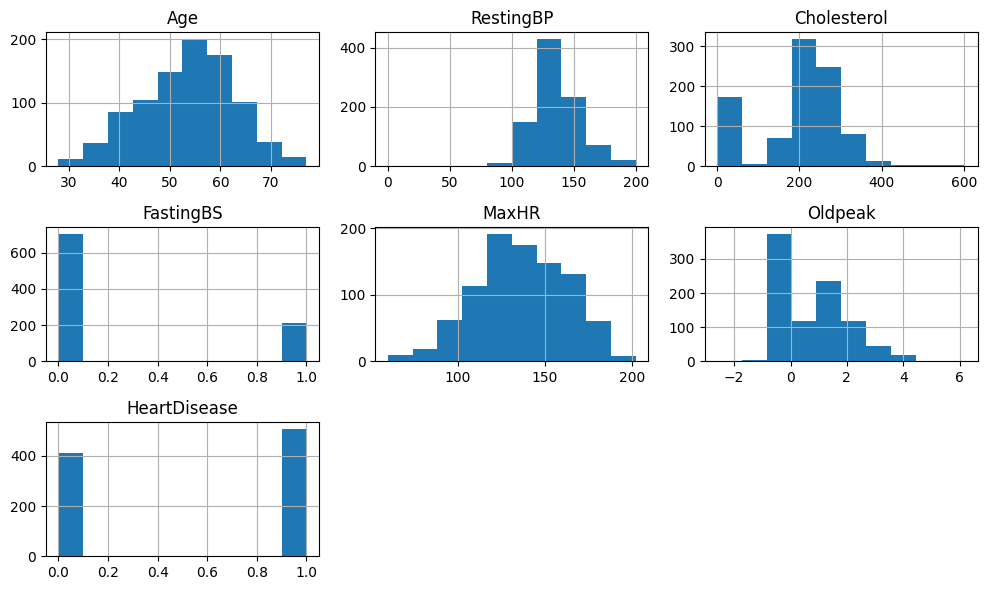

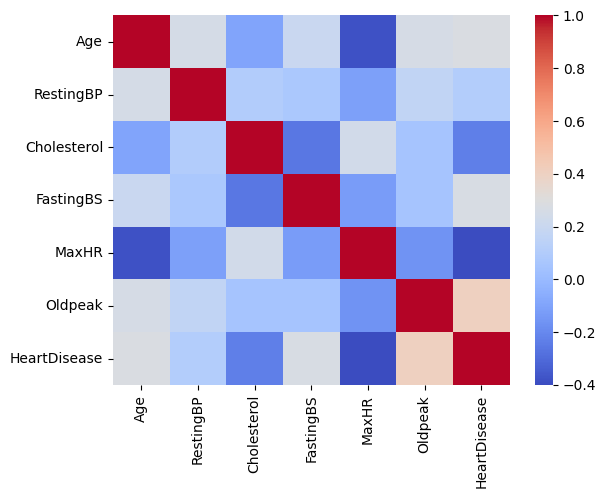

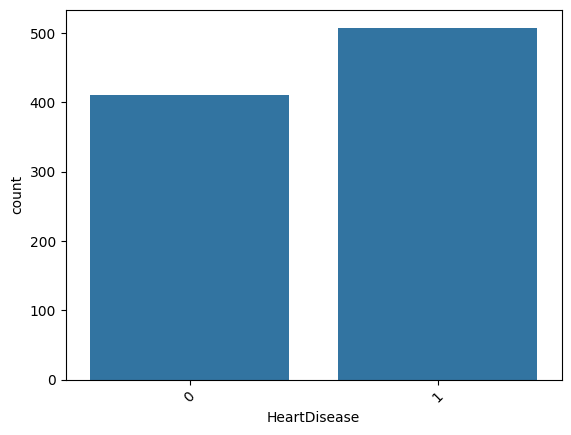


Without PCA best parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
Without PCA CV accuracy: 0.8542633491752867

With PCA best parameters: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}
With PCA CV accuracy: 0.8597148448420464

 Without PCA
Accuracy: 0.8967391304347826
Precision: 0.8973163163532931
Recall: 0.8967391304347826
F1-score: 0.8963507097223259
Confusion matrix:
 [[70 12]
 [ 7 95]]
              precision    recall  f1-score   support

           0       0.91      0.85      0.88        82
           1       0.89      0.93      0.91       102

    accuracy                           0.90       184
   macro avg       0.90      0.89      0.89       184
weighted avg       0.90      0.90      0.90       184


 With PCA
Accuracy: 0.8967391304347826
Precision: 0.8982329477463104
Recall: 0.8967391304347826
F1-score: 0.896149994553241
Confusion matrix:
 [[69 13]
 [ 6 96]]
              precision    recall  f1-score   support

           0    

In [1]:

# ============ CLASSIFICATION: PCA vs WITHOUT PCA ============

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_rel

from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, cross_validate
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

# ================= 1. LOAD DATASET =================
df = pd.read_csv("heart.csv")
target = "HeartDisease"                    # Change target column
df = df.drop_duplicates()
df = df.drop(columns=["id"], errors="ignore")

# ================= 2. EDA =================
print(df.info())
print(df.describe(include="all"))
print("\nMissing values:\n", df.isnull().sum())

df.select_dtypes(include=np.number).hist(figsize=(10, 6))
plt.tight_layout()
plt.show()

sns.heatmap(df.select_dtypes(include=np.number).corr(),
            cmap="coolwarm")
plt.show()

sns.countplot(data=df, x=target)
plt.xticks(rotation=45)
plt.show()

# ================= 3. FEATURES & TARGET =================
X = df.drop(columns=target)
y = df[target]

# Encode categorical target labels
if y.dtype == "object" or isinstance(y.dtype, pd.CategoricalDtype):
    y = LabelEncoder().fit_transform(y.astype(str))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num = X.select_dtypes(include=np.number).columns.tolist()
cat = X.select_dtypes(exclude=np.number).columns.tolist()

# ================= 4. PREPROCESSING =================
prep = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore",
                                  sparse_output=False))
    ]), cat)
])

# ================= 5. MODELS =================
pipe1 = Pipeline([
    ("prep", prep),
    ("model", SVC())
])

pipe2 = Pipeline([
    ("prep", prep),
    ("pca", PCA(n_components=0.95)),
    ("model", SVC())
])

params = {
    "model__C": [0.1, 1, 10],
    "model__gamma": ["scale", 0.1],
    "model__kernel": ["rbf"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ================= 6. HYPERPARAMETER TUNING =================
grid1 = GridSearchCV(
    pipe1, params, cv=cv, scoring="accuracy", n_jobs=-1
)
grid2 = GridSearchCV(
    pipe2, params, cv=cv, scoring="accuracy", n_jobs=-1
)

grid1.fit(X_train, y_train)
grid2.fit(X_train, y_train)

print("\nWithout PCA best parameters:", grid1.best_params_)
print("Without PCA CV accuracy:", grid1.best_score_)

print("\nWith PCA best parameters:", grid2.best_params_)
print("With PCA CV accuracy:", grid2.best_score_)

# ================= 7. PERFORMANCE METRICS =================
for name, model in [
    ("Without PCA", grid1.best_estimator_),
    ("With PCA", grid2.best_estimator_)
]:
    pred = model.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(
        y_test, pred, average="weighted", zero_division=0
    ))
    print("Recall:", recall_score(
        y_test, pred, average="weighted", zero_division=0
    ))
    print("F1-score:", f1_score(
        y_test, pred, average="weighted", zero_division=0
    ))
    print("Confusion matrix:\n", confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, zero_division=0))

    if "pca" in model.named_steps:
        pca = model.named_steps["pca"]
        print("PCA components:", pca.n_components_)
        print("Explained variance:", pca.explained_variance_ratio_.sum())

# ================= 8. CROSS-VALIDATION SCORES =================
scores1 = cross_validate(
    grid1.best_estimator_, X_train, y_train,
    cv=cv, scoring=["accuracy", "f1_weighted"]
)

scores2 = cross_validate(
    grid2.best_estimator_, X_train, y_train,
    cv=cv, scoring=["accuracy", "f1_weighted"]
)

print("\nMean CV accuracy without PCA:",
      scores1["test_accuracy"].mean())
print("Mean CV accuracy with PCA:",
      scores2["test_accuracy"].mean())

print("Mean CV F1 without PCA:",
      scores1["test_f1_weighted"].mean())
print("Mean CV F1 with PCA:",
      scores2["test_f1_weighted"].mean())

# ================= 9. PAIRED T-TEST =================
t_stat, p_value = ttest_rel(
    scores1["test_accuracy"], scores2["test_accuracy"]
)

print("\nAccuracy paired t-test")
print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Significant difference in accuracy")
else:
    print("No significant difference in accuracy")

t_stat, p_value = ttest_rel(
    scores1["test_f1_weighted"], scores2["test_f1_weighted"]
)

print("\nF1-score paired t-test")
print("t-statistic:", t_stat)
print("p-value:", p_value)

if p_value < 0.05:
    print("Significant difference in F1-score")
else:
    print("No significant difference in F1-score")
